# Multi-label classification — train and evaluate

Training is one call; the interesting part is *reading what comes out*. This notebook trains, plots the learning curves, evaluates on the test split, and shows you how to interpret each number.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/multilabel/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("multilabel", cfg)
print("task:", "multilabel", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: multilabel | data: data/demo/multilabel | outputs: outputs/multilabel_quick


## The configuration
Everything tunable is in one YAML file. These are the sections that matter:

In [3]:
import yaml

for section in ('data', 'model', 'train'):
    print(section + ':')
    for line in yaml.safe_dump(cfg[section], sort_keys=False).splitlines():
        print('  ' + line)

data:
  root: data/demo/multilabel
  images_dir: images
  labels_file: labels.csv
  image_size: 96
  batch_size: 16
  num_workers: 0
  split:
    train: 0.7
    val: 0.15
    test: 0.15
  augment:
    hflip: true
    vflip: true
    rotation: 0
    color_jitter: 0.0
    random_erasing: 0.0
model:
  arch: resnet18
  pretrained: false
  freeze_backbone: false
  dropout: 0.2
train:
  epochs: 15
  lr: 0.002
  weight_decay: 0.0001
  pos_weight: false
  amp: true
  early_stopping_patience: 0


## What are we about to train?

In [4]:
from cvkit.utils import count_parameters
from tasks.multilabel.data import build_loaders
from tasks.multilabel.model import build_model

classes = build_loaders(cfg)["classes"]
model = build_model(cfg, {"classes": classes})
p = count_parameters(model)
print(f"arch {cfg['model']['arch']} | pretrained {cfg['model']['pretrained']} | {len(classes)} labels: {classes}")
print(f"{p['total']:,} parameters, {p['trainable']:,} trainable ({p['trainable_pct']:.0f}%)")
print("loss: BCEWithLogits - an independent sigmoid per label (single-label classification uses a softmax instead)")
del model

arch resnet18 | pretrained False | 3 labels: ['circle', 'square', 'triangle']
11,178,051 parameters, 11,178,051 trainable (100%)
loss: BCEWithLogits - an independent sigmoid per label (single-label classification uses a softmax instead)


## Train
Watch the `val` numbers: they are what picks the best epoch.

In [5]:
from tasks.multilabel.train import train

result = train(cfg)
print('\nbest epoch:', result['best_epoch'], '|', {k: round(v, 4) for k, v in result['best_metrics'].items()})

arch: resnet18 | labels (3): ['circle', 'square', 'triangle']
device: cpu | parameters: 11,178,051 total, 11,178,051 trainable (100.0%)


epoch   1/15 | train_loss 0.7370 | val loss=3.158 f1_macro=0.495 f1_micro=0.611 map=0.732 exact=0.162 | 3.0s  <- best


epoch   2/15 | train_loss 0.5980 | val loss=0.799 f1_macro=0.525 f1_micro=0.560 map=0.879 exact=0.250 | 2.9s  <- best


epoch   3/15 | train_loss 0.5516 | val loss=0.652 f1_macro=0.557 f1_micro=0.587 map=0.880 exact=0.250 | 2.7s  <- best


epoch   4/15 | train_loss 0.5025 | val loss=0.830 f1_macro=0.590 f1_micro=0.642 map=0.832 exact=0.309 | 2.9s


...

epoch  11/15 | train_loss 0.1598 | val loss=0.260 f1_macro=0.885 f1_micro=0.886 map=0.972 exact=0.676 | 3.0s  <- best


epoch  12/15 | train_loss 0.0940 | val loss=0.074 f1_macro=0.978 f1_micro=0.978 map=1.000 exact=0.926 | 3.0s  <- best


epoch  13/15 | train_loss 0.0650 | val loss=0.041 f1_macro=0.992 f1_micro=0.991 map=1.000 exact=0.971 | 2.9s  <- best


epoch  14/15 | train_loss 0.0435 | val loss=0.027 f1_macro=0.996 f1_micro=0.996 map=1.000 exact=0.985 | 2.8s


epoch  15/15 | train_loss 0.0333 | val loss=0.028 f1_macro=0.996 f1_micro=0.996 map=1.000 exact=0.985 | 2.8s
best val map = 1.0000 (epoch 13) -> outputs/multilabel_quick/checkpoints/best.pt

best epoch: 13 | {'loss': 0.041, 'f1_macro': 0.9921, 'f1_micro': 0.9915, 'map': 1.0, 'exact': 0.9706}


## Learning curves
**Gap widening** between train and val → overfitting (more augmentation, fewer epochs, smaller model). **Both flat and poor** → underfitting (train longer, raise the learning rate, unfreeze the backbone). **Val bouncing hard** → learning rate too high, or the val split is small. Remember the quick preset trains for only a few epochs, so expect curves still on their way up. Here **map** is average precision (higher is better) and `label_acc` is per-label accuracy at the threshold.

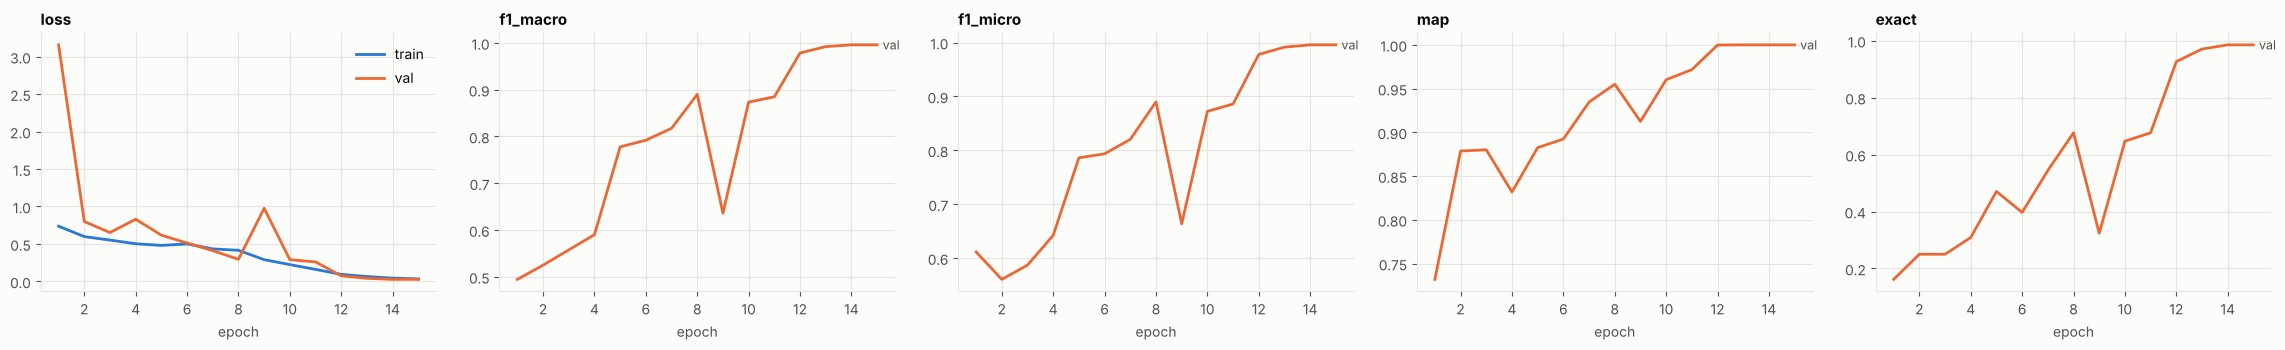

In [6]:
from cvkit.viz import plot_history

_ = plot_history(Path(cfg['output']['dir']) / 'history.csv')

## Evaluate on the test split
Val chose the checkpoint; the **test split** was untouched until now, so it is the honest number. One rule: look at test results, *don't tune on them* — the moment you tweak settings to chase the test score, it stops measuring generalisation.

In [7]:
from tasks.multilabel.evaluate import evaluate

metrics = evaluate(cfg)

threshold 0.5: mAP 1.0000 | macro-F1 0.9956 | micro-F1 0.9951 | exact-match 0.9853
              precision    recall  f1-score   support

      circle      1.000     1.000     1.000        31
      square      0.974     1.000     0.987        37
    triangle      1.000     1.000     1.000        34

   micro avg      0.990     1.000     0.995       102
   macro avg      0.991     1.000     0.996       102
weighted avg      0.990     1.000     0.995       102
 samples avg      0.993     1.000     0.995       102

reports -> outputs/multilabel_quick/reports


per_label_metrics.png


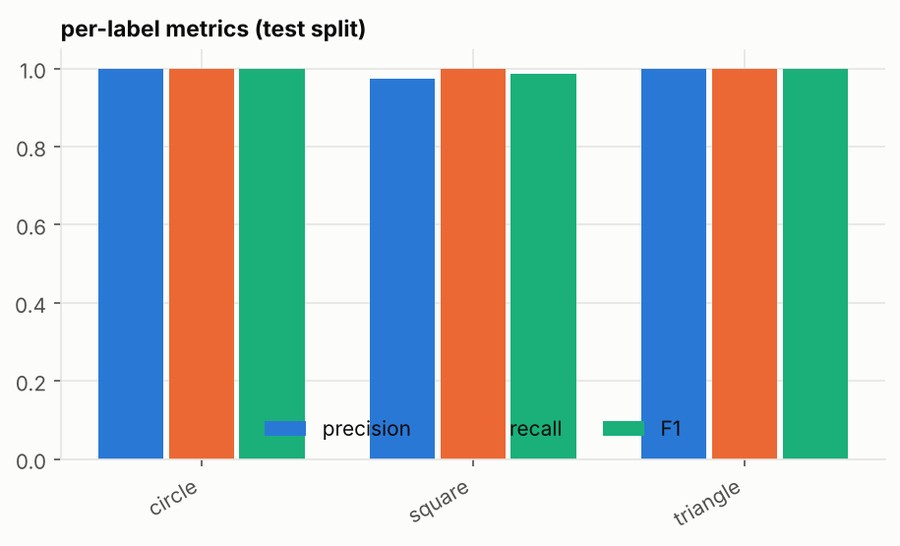

threshold_sweep.png


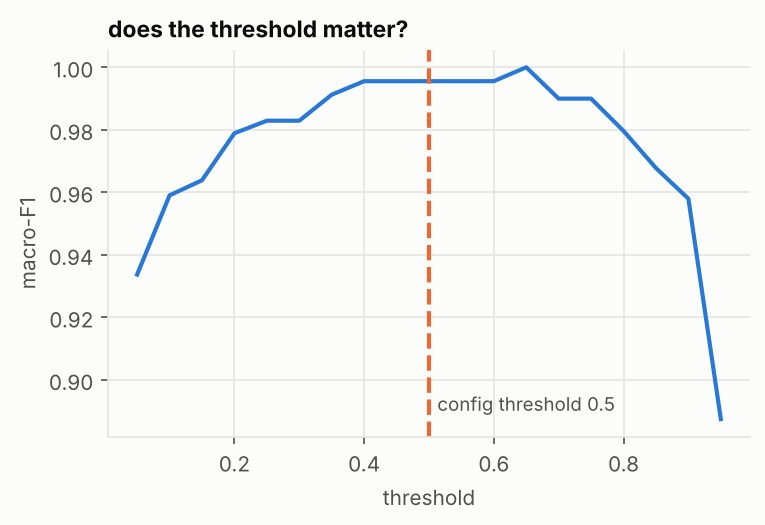

worst_images.png


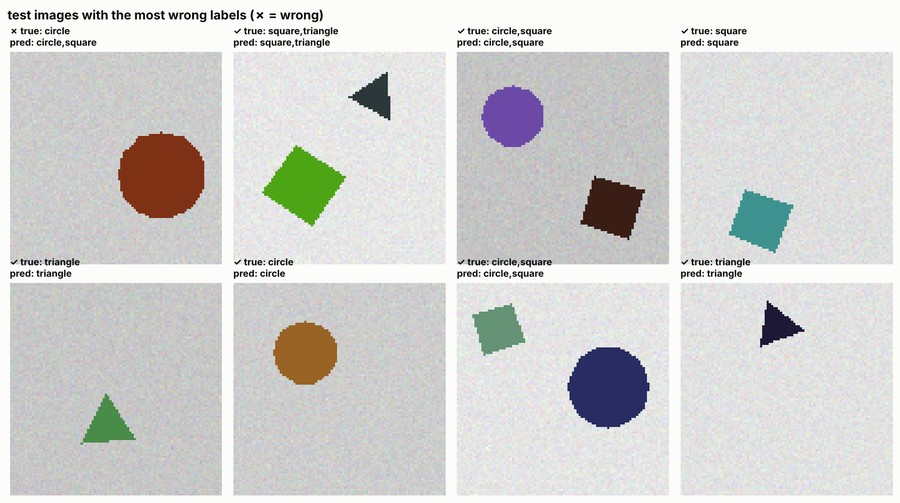

In [8]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['per_label_metrics.png', 'threshold_sweep.png', 'worst_images.png']:
    print(name)
    show_image(reports / name)

## How to read these results
* **mAP** — average precision per label, averaged. It does not depend on the 0.5 cut-off: it measures how well the model *ranks* images for each label. Use it to compare models; it picked the best epoch.
* **Precision / recall / F1 per label** — at the configured threshold. A rare label usually shows high precision, low recall.
* **Macro-F1 vs micro-F1** — macro averages labels equally (a rare label matters as much as a common one); micro pools every decision (dominated by the common labels).
* **Exact match** — the share of images where the *whole label set* is right. Harsh: one wrong label out of five fails the image.
* **Threshold sweep** — if the curve peaks away from 0.5, change `eval.threshold`. Pick it on *val*, not on test.
* **Worst images** — compare true and predicted sets: are missed labels small or occluded? are false labels look-alikes?

## Experiments worth running
Each one is a one-line change. Re-run the training cell with a different config and compare the best val numbers (change `cfg` like this, then re-run from *Train*):

```python
cfg['model']['arch'] = 'resnet34'     # or any key, same as --set model.arch=resnet34
```

1. `train.pos_weight = True` — up-weights rare labels; watch recall on the rarest label
2. `eval.threshold = 0.3` vs `0.7` — see the precision/recall trade in the report
3. `model.arch = 'resnet34'` — does capacity help?
4. `model.freeze_backbone = True` — feature extraction only

Change **one thing at a time**, keep the seed, and write down what you changed — otherwise you can't tell what helped.

Next: **[03_predict_and_deploy](03_predict_and_deploy.ipynb)**.